# **Практическая работа. Геоанализ экологических факторов городской среды с применением методов пространственной кластеризации**




















## **Цель работы**



Освоение методов пространственного анализа и машинного обучения для оценки экологической обстановки городской территории с использованием гексагональной сетки H3, с последующим применением различных алгоритмов кластеризации и классификации.

## **Задачи**



1. Освоить инструменты загрузки и агрегации экологических геоданных с использованием API OpenStreetMap
2. Реализовать анализ пространственного распределения экологических факторов с помощью гексагональной сетки H3
3. Применить и сравнить различные алгоритмы кластеризации для выявления однородных экологических зон
4. Обучить модели классификации для прогнозирования экологического состояния новых территорий

## **Теоретическая часть**



Современный геоэкологический анализ требует комплексного подхода к обработке пространственно-распределенных данных. Применение методов машинного обучения, в частности алгоритмов кластеризации (K-means, агломеративной, спектральной, DBSCAN, HDBSCAN), позволяет выявлять неявные закономерности в распределении экологических факторов городской среды и определять территории со схожими экологическими характеристиками.

## **Этапы работы**



### **1. Определение области исследования и подготовка данных**


- Выберите городскую территорию для анализа экологической обстановки
- Используя API OpenStreetMap, загрузите данные следующих категорий:
  - Источники загрязнения (промышленные предприятия, мусоропереработка, ТЭЦ)
  - Зеленые насаждения (парки, скверы, лесопарковые зоны)
  - Водные объекты (реки, водоемы)
  - Автомагистрали (категории дорог с интенсивным движением)
  - Административные районы города

Территория: центральная часть Санкт-Петербурга
Источник данных: локально сгенерированные учебные геоданные
Источники загрязнения: 18
Зеленые зоны: 35
Водные объекты: 2
Крупные дороги: 8


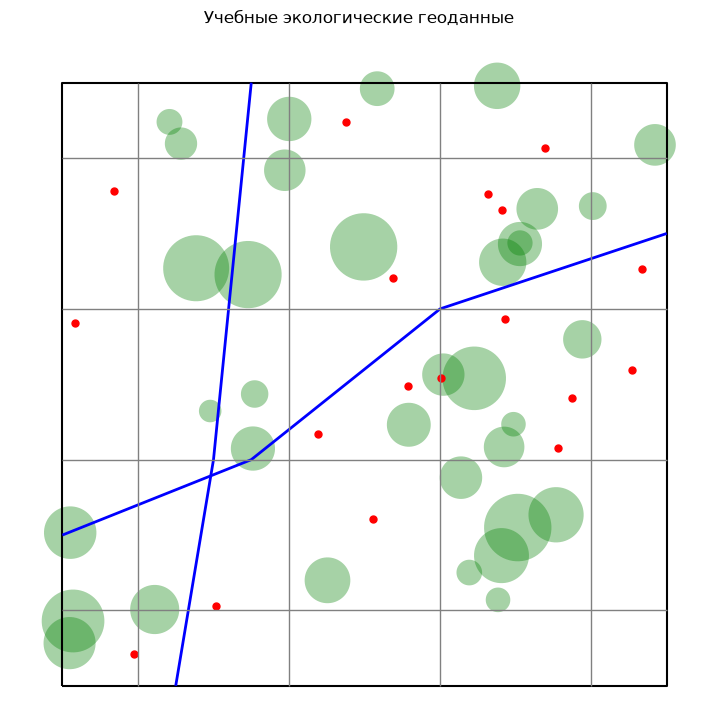

In [1]:
# Полностью офлайн-версия: OpenStreetMap и интернет не используются

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import h3

from shapely.geometry import Point, LineString, Polygon, box

print("Территория: центральная часть Санкт-Петербурга")
print("Источник данных: локально сгенерированные учебные геоданные")

# Границы исследуемой территории
north = 59.955
south = 59.915
east = 30.365
west = 30.285

roi_geom = box(west, south, east, north)

roi = gpd.GeoDataFrame(
    {"name": ["Центральная часть Санкт-Петербурга"]},
    geometry=[roi_geom],
    crs="EPSG:4326"
)

# Вспомогательные функции
def random_points(n):
    lon = np.random.uniform(west, east, n)
    lat = np.random.uniform(south, north, n)
    return [Point(x, y) for x, y in zip(lon, lat)]

# Источники загрязнения: промышленные/технические объекты
pollution = gpd.GeoDataFrame(
    {"type": ["pollution"] * 18},
    geometry=random_points(18),
    crs="EPSG:4326"
)

# Зеленые зоны: центры будущих буферных полигонов
green_centers = gpd.GeoDataFrame(
    {"type": ["green"] * 35},
    geometry=random_points(35),
    crs="EPSG:4326"
)

# Водные объекты: несколько линий, имитирующих каналы/реки
water_lines = [
    LineString([
        (west, 59.925),
        (30.310, 59.930),
        (30.335, 59.940),
        (east, 59.945)
    ]),
    LineString([
        (30.300, south),
        (30.305, 59.930),
        (30.310, north)
    ])
]

water = gpd.GeoDataFrame(
    {"type": ["water"] * len(water_lines)},
    geometry=water_lines,
    crs="EPSG:4326"
)

# Крупные дороги: горизонтальные и вертикальные линии
road_lines = []

for lat in [59.920, 59.930, 59.940, 59.950]:
    road_lines.append(
        LineString([(west, lat), (east, lat)])
    )

for lon in [30.295, 30.315, 30.335, 30.355]:
    road_lines.append(
        LineString([(lon, south), (lon, north)])
    )

roads = gpd.GeoDataFrame(
    {"type": ["road"] * len(road_lines)},
    geometry=road_lines,
    crs="EPSG:4326"
)

# Для площади зелени переводим центры в метрическую CRS и делаем буферы
green_m = green_centers.to_crs("EPSG:32636")
green_m["geometry"] = green_m.buffer(
    np.random.uniform(80, 250, len(green_m))
)
green = green_m.to_crs("EPSG:4326")

print("Источники загрязнения:", len(pollution))
print("Зеленые зоны:", len(green))
print("Водные объекты:", len(water))
print("Крупные дороги:", len(roads))

# Визуализация исходных слоев
ax = roi.boundary.plot(figsize=(9, 9), color="black")

green.plot(
    ax=ax,
    color="green",
    alpha=0.35
)

water.plot(
    ax=ax,
    color="blue",
    linewidth=2
)

roads.plot(
    ax=ax,
    color="gray",
    linewidth=1
)

pollution.plot(
    ax=ax,
    color="red",
    markersize=25
)

plt.title("Учебные экологические геоданные")
plt.axis("off")
plt.show()

### **2. Агрегация данных с использованием гексагональной сетки H3**


- Сгенерируйте гексагональную сетку H3 оптимального разрешения для выбранной территории
- Для каждой ячейки H3 рассчитайте:
  - Количество и плотность источников загрязнения в радиусе 1600м
  - Площадь и процент покрытия зелеными насаждениями в радиусе 800м
  - Протяженность водных объектов в радиусе 1600м
  - Плотность автомагистралей в радиусе 1600м
- Выполните нормализацию полученных показателей
- Сформируйте интегральный индекс экологического благополучия территории


Количество H3-ячеек: 32


,count,mean,std,min,25%,50%,75%,max
pollution_count_1600,32.0,5.500000,3.037401,1.000000,2.750000,5.500000,7.250000,13.000000
pollution_density_1600,32.0,0.683869,0.377670,0.124340,0.341934,0.683869,0.901464,1.616417
green_area_800,32.0,284607.301622,185958.760276,2437.262425,129283.305304,282585.600027,397298.295759,836513.314703
green_share_800,32.0,14.155206,9.248830,0.121219,6.430024,14.054655,19.759996,41.604759
water_length_1000,32.0,1359.035037,1194.294230,0.000000,0.000000,1404.245246,1993.549896,3987.867572
road_length_1000,32.0,4673.029613,1232.458265,2484.342712,3545.587539,4851.057624,5719.985590,6498.440395
road_density_1000,32.0,1.487472,0.392304,0.790791,1.128596,1.544140,1.820728,2.068518
dist_pollution,32.0,537.852080,306.429582,99.439098,332.262807,492.889300,731.034735,1219.682777
dist_green,32.0,254.636996,203.413276,0.000000,115.821539,212.737773,356.971882,778.337293
dist_water,32.0,737.174915,566.419470,96.941198,332.568060,643.185888,1041.284223,2444.069695


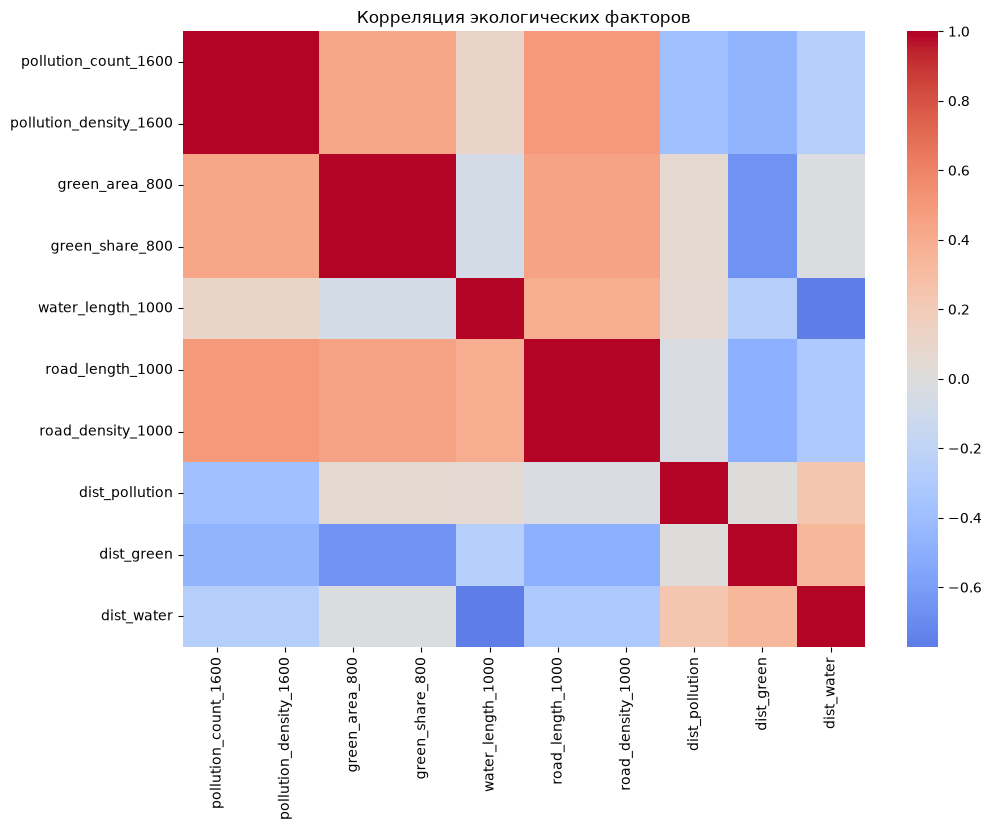

In [2]:
# H3-сетка
resolution = 8

cells = list(
    h3.geo_to_cells(
        roi.geometry.iloc[0].__geo_interface__,
        resolution
    )
)

def cell_polygon(cell):
    coords = h3.cell_to_boundary(cell)
    return Polygon([
        (lng, lat)
        for lat, lng in coords
    ])

grid = gpd.GeoDataFrame(
    {"h3": cells},
    geometry=[
        cell_polygon(c)
        for c in cells
    ],
    crs="EPSG:4326"
)

print("Количество H3-ячеек:", len(grid))

# Метрическая проекция
grid_m = grid.to_crs("EPSG:32636")
grid_m["center"] = grid_m.centroid

centers = gpd.GeoDataFrame(
    grid_m[["h3"]].copy(),
    geometry=grid_m["center"],
    crs="EPSG:32636"
)

pollution_m = pollution.to_crs("EPSG:32636")
green_m = green.to_crs("EPSG:32636")
water_m = water.to_crs("EPSG:32636")
roads_m = roads.to_crs("EPSG:32636")

# Буферы вокруг центров ячеек
buf1600 = centers.copy()
buf1600["geometry"] = centers.buffer(1600)

buf800 = centers.copy()
buf800["geometry"] = centers.buffer(800)

buf1000 = centers.copy()
buf1000["geometry"] = centers.buffer(1000)

# 1. Количество источников загрязнения в радиусе 1600 м
joined = gpd.sjoin(
    pollution_m[["geometry"]],
    buf1600[["h3", "geometry"]],
    predicate="within"
)

a = joined.groupby("h3").size()

grid["pollution_count_1600"] = (
    grid["h3"]
    .map(a)
    .fillna(0)
    .astype(int)
)

# 2. Плотность источников загрязнения
grid["pollution_density_1600"] = (
    grid["pollution_count_1600"] /
    (np.pi * 1.6 ** 2)
)

# 3-4. Площадь и доля зеленых зон в радиусе 800 м
green_intersections = gpd.overlay(
    green_m[["geometry"]],
    buf800[["h3", "geometry"]],
    how="intersection"
)

green_intersections["area"] = (
    green_intersections.geometry.area
)

a = (
    green_intersections
    .groupby("h3")["area"]
    .sum()
)

grid["green_area_800"] = (
    grid["h3"]
    .map(a)
    .fillna(0)
)

grid["green_share_800"] = (
    grid["green_area_800"] /
    (np.pi * 800 ** 2) * 100
).clip(0, 100)

# 5. Протяженность воды в радиусе 1000 м
water_intersections = gpd.overlay(
    water_m[["geometry"]],
    buf1000[["h3", "geometry"]],
    how="intersection"
)

water_intersections["length"] = (
    water_intersections.geometry.length
)

a = (
    water_intersections
    .groupby("h3")["length"]
    .sum()
)

grid["water_length_1000"] = (
    grid["h3"]
    .map(a)
    .fillna(0)
)

# 6. Протяженность крупных дорог
road_intersections = gpd.overlay(
    roads_m[["geometry"]],
    buf1000[["h3", "geometry"]],
    how="intersection"
)

road_intersections["length"] = (
    road_intersections.geometry.length
)

a = (
    road_intersections
    .groupby("h3")["length"]
    .sum()
)

grid["road_length_1000"] = (
    grid["h3"]
    .map(a)
    .fillna(0)
)

# 7. Плотность дорог
grid["road_density_1000"] = (
    grid["road_length_1000"] /
    (np.pi * 1.0 ** 2) /
    1000
)

# 8. Расстояние до ближайшего источника загрязнения
pollution_union = pollution_m.geometry.union_all()

grid["dist_pollution"] = centers.geometry.apply(
    lambda x: x.distance(pollution_union)
).values

# 9. Расстояние до ближайшей зеленой зоны
green_union = green_m.geometry.union_all()

grid["dist_green"] = centers.geometry.apply(
    lambda x: x.distance(green_union)
).values

# 10. Расстояние до ближайшего водного объекта
water_union = water_m.geometry.union_all()

grid["dist_water"] = centers.geometry.apply(
    lambda x: x.distance(water_union)
).values

feature_cols = [
    "pollution_count_1600",
    "pollution_density_1600",
    "green_area_800",
    "green_share_800",
    "water_length_1000",
    "road_length_1000",
    "road_density_1000",
    "dist_pollution",
    "dist_green",
    "dist_water"
]

# Проверка пропусков
for col in feature_cols:
    grid[col] = (
        grid[col]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
    )

display(
    grid[feature_cols]
    .describe()
    .T
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    grid[feature_cols].corr(),
    cmap="coolwarm",
    center=0
)

plt.title(
    "Корреляция экологических факторов"
)

plt.show()

### **3. Определение оптимального числа кластеров**


- Постройте график метода локтя (Elbow method) для определения оптимального числа кластеров
- Оцените качество кластеризации с помощью внутренних метрик кластеризации
- Определите оптимальное число кластеров на основе комбинации различных метрик

C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,213.214778,0.283651,1.264206,15.025022
1,3,167.533755,0.225350,1.298416,13.195911
2,4,143.088998,0.232457,1.257862,11.539457
3,5,120.766212,0.240507,1.139254,11.135797
4,6,105.111388,0.223336,1.196458,10.630825
5,7,94.217635,0.234977,1.167854,9.984966
6,8,88.570117,0.230087,0.968015,8.958709


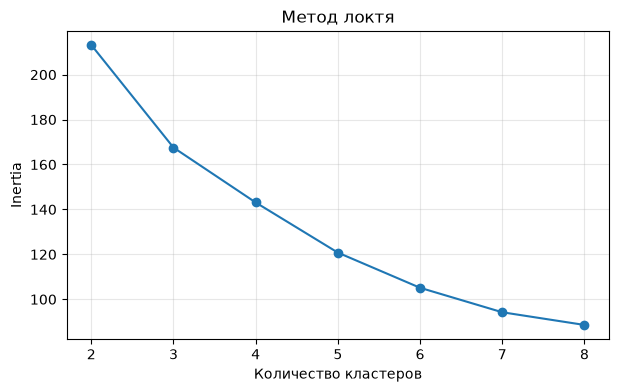

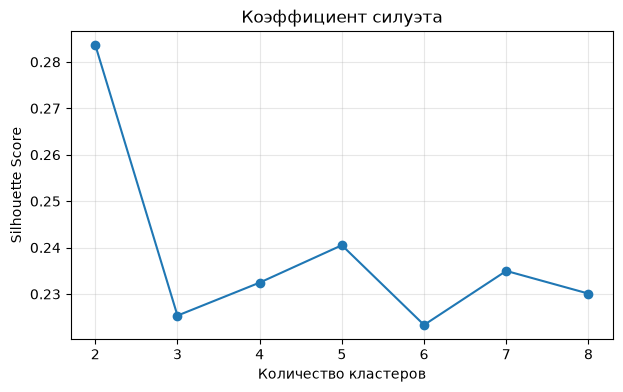

Оптимальное количество кластеров: 2


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

X = grid[feature_cols].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rows = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10)
    labels = model.fit_predict(X_scaled)

    rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels),
        "calinski_harabasz": calinski_harabasz_score(X_scaled, labels)
    })

scores = pd.DataFrame(rows)
display(scores)

plt.figure(figsize=(7, 4))
plt.plot(scores["k"], scores["inertia"], marker="o")
plt.xlabel("Количество кластеров")
plt.ylabel("Inertia")
plt.title("Метод локтя")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(scores["k"], scores["silhouette"], marker="o")
plt.xlabel("Количество кластеров")
plt.ylabel("Silhouette Score")
plt.title("Коэффициент силуэта")
plt.grid(alpha=0.3)
plt.show()

best_k = int(
    scores.sort_values(
        ["silhouette", "davies_bouldin"],
        ascending=[False, True]
    ).iloc[0]["k"]
)

print("Оптимальное количество кластеров:", best_k)

### **4. Сравнительный анализ алгоритмов кластеризации**


- Реализуйте и сравните следующие алгоритмы кластеризации:
  - K-means
  - Агломеративная кластеризация
  - Спектральная кластеризация
  - DBSCAN (с оптимальным значением eps)
  - HDBSCAN
- Для каждого алгоритма оцените:
  - Качество кластеризации по основным метрикам
  - Распределение точек по кластерам
  - Характерные особенности выявленных кластеров

In [4]:
from sklearn.cluster import (
    AgglomerativeClustering,
    SpectralClustering,
    DBSCAN,
    HDBSCAN
)
from sklearn.neighbors import NearestNeighbors

# Подбор eps для DBSCAN через расстояние до 5-го соседа
neighbors = NearestNeighbors(n_neighbors=5)
neighbors.fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)

eps = np.percentile(
    np.sort(distances[:, -1]),
    90
)

print("Выбранный eps для DBSCAN:", round(eps, 3))

algorithms = {
    "KMeans": KMeans(n_clusters=best_k, n_init=10),
    "Agglomerative": AgglomerativeClustering(n_clusters=best_k),
    "Spectral": SpectralClustering(
        n_clusters=best_k,
        affinity="nearest_neighbors",
        assign_labels="kmeans"
    ),
    "DBSCAN": DBSCAN(
        eps=eps,
        min_samples=5
    ),
    "HDBSCAN": HDBSCAN(
        min_cluster_size=max(5, len(grid) // 50),
        min_samples=5
    )
}

comparison = []
labels_dict = {}

for name, model in algorithms.items():
    labels = model.fit_predict(X_scaled)
    labels_dict[name] = labels

    mask = labels != -1
    labels_clean = labels[mask]
    X_clean = X_scaled[mask]

    n_clusters = len(set(labels_clean))

    if n_clusters >= 2:
        comparison.append({
            "algorithm": name,
            "clusters": n_clusters,
            "noise": int((labels == -1).sum()),
            "silhouette": silhouette_score(X_clean, labels_clean),
            "davies_bouldin": davies_bouldin_score(X_clean, labels_clean),
            "calinski_harabasz": calinski_harabasz_score(
                X_clean,
                labels_clean
            )
        })
    else:
        comparison.append({
            "algorithm": name,
            "clusters": n_clusters,
            "noise": int((labels == -1).sum()),
            "silhouette": np.nan,
            "davies_bouldin": np.nan,
            "calinski_harabasz": np.nan
        })

comparison = pd.DataFrame(comparison)
display(comparison.sort_values("silhouette", ascending=False))

best_algorithm = (
    comparison.dropna(subset=["silhouette"])
    .sort_values(
        ["silhouette", "davies_bouldin"],
        ascending=[False, True]
    )
    .iloc[0]["algorithm"]
)

grid["cluster"] = labels_dict[best_algorithm]

print("Лучший алгоритм:", best_algorithm)
print("Распределение:")
print(grid["cluster"].value_counts().sort_index())

Выбранный eps для DBSCAN: 3.554


C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,algorithm,clusters,noise,silhouette,davies_bouldin,calinski_harabasz
0,KMeans,2,0,0.283651,1.264206,15.025022
1,Agglomerative,2,0,0.279507,1.237532,14.555153
2,Spectral,2,0,0.267351,1.311495,14.600679
3,DBSCAN,1,0,NaN,NaN,NaN
4,HDBSCAN,0,32,NaN,NaN,NaN


Лучший алгоритм: KMeans
Распределение:
cluster
0    21
1    11
Name: count, dtype: int64


### **5. Визуализация и интерпретация результатов**


- Визуализируйте результаты кластеризации на карте с использованием leafmap
- Постройте тепловые карты средних значений экологических факторов для каждого кластера
- Выполните снижение размерности с помощью PCA и визуализируйте кластеры в двумерном пространстве
- Проанализируйте профили кластеров и составьте их экологические характеристики
- Разработайте рекомендации по улучшению экологической обстановки для каждого типа территории

C:\Users\jopna\AppData\Local\Temp\ipykernel_28048\663901433.py:9: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  grid_map.geometry.centroid.y.mean(),
C:\Users\jopna\AppData\Local\Temp\ipykernel_28048\663901433.py:10: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  grid_map.geometry.centroid.x.mean()


,pollution_count_1600,pollution_density_1600,green_area_800,green_share_800,water_length_1000,road_length_1000,road_density_1000,dist_pollution,dist_green,dist_water
cluster,,,,,,,,,,
0,6.476190,0.805248,365544.580988,18.180696,1748.911742,5431.751025,1.72898,524.809745,172.277562,579.377951
1,3.636364,0.452145,130090.677379,6.470179,614.724962,3224.561462,1.02641,562.751085,411.868643,1038.423664


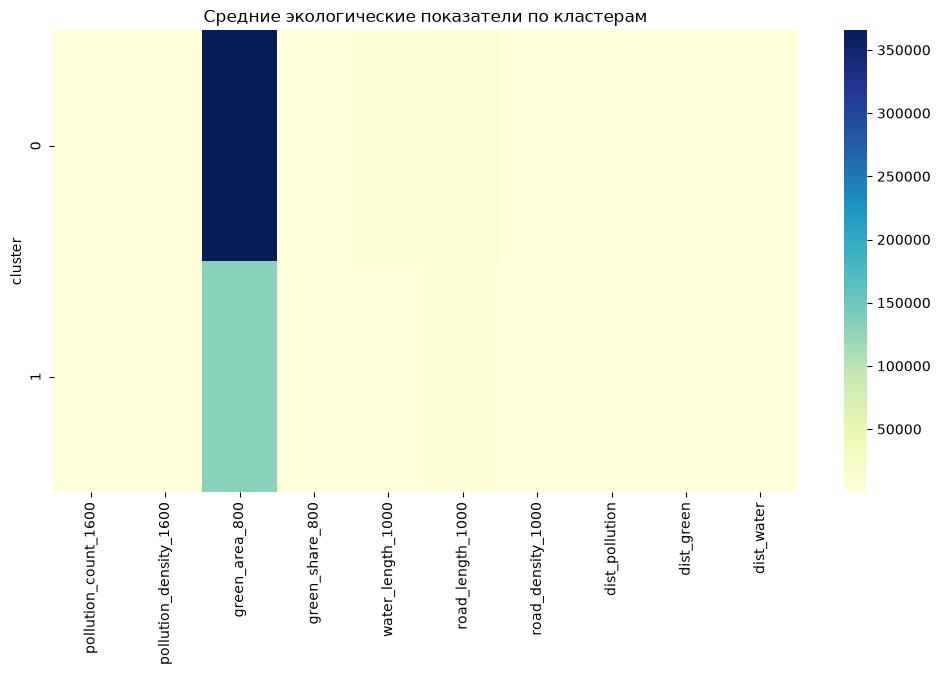

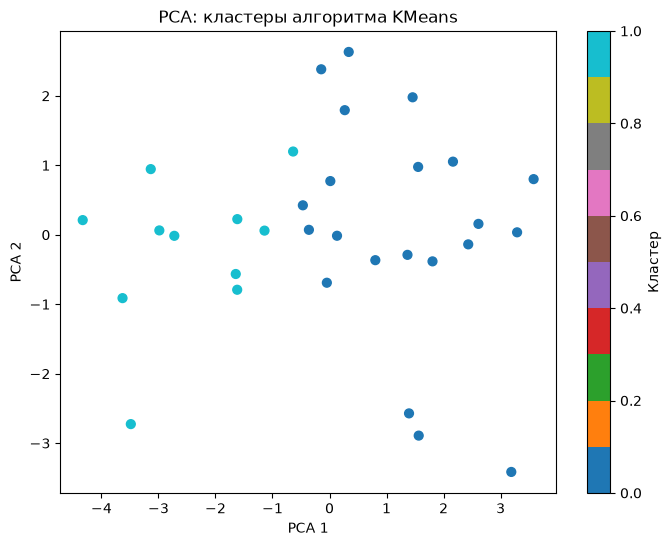

,pollution_count_1600,pollution_density_1600,green_area_800,green_share_800,water_length_1000,road_length_1000,road_density_1000,dist_pollution,dist_green,dist_water,eco_score
cluster,,,,,,,,,,,
0,6.476190,0.805248,365544.580988,18.180696,1748.911742,5431.751025,1.72898,524.809745,172.277562,579.377951,0.0
1,3.636364,0.452145,130090.677379,6.470179,614.724962,3224.561462,1.02641,562.751085,411.868643,1038.423664,0.0


Чем выше eco_score, тем более благоприятным считается экологический профиль кластера.


In [7]:
from sklearn.decomposition import PCA
import folium
import branca.colormap as cm

# Интерактивная карта через folium
grid_map = grid.to_crs("EPSG:4326").copy()

center = [
    grid_map.geometry.centroid.y.mean(),
    grid_map.geometry.centroid.x.mean()
]

m = folium.Map(
    location=center,
    zoom_start=13,
    tiles="CartoDB positron"
)

colors = [
    "blue", "green", "orange", "red",
    "purple", "cadetblue", "darkred",
    "darkgreen", "darkblue", "gray"
]

for _, row in grid_map.iterrows():
    cluster = int(row["cluster"])
    color = colors[cluster % len(colors)] if cluster >= 0 else "black"

    folium.GeoJson(
        row.geometry.__geo_interface__,
        style_function=lambda x, c=color: {
            "fillColor": c,
            "color": c,
            "weight": 1,
            "fillOpacity": 0.45
        },
        tooltip=f"Кластер: {cluster}"
    ).add_to(m)

m

# Средние значения факторов
cluster_profile = (
    grid[grid["cluster"] != -1]
    .groupby("cluster")[feature_cols]
    .mean()
)

display(cluster_profile)

plt.figure(figsize=(12, 6))
sns.heatmap(
    cluster_profile,
    cmap="YlGnBu"
)
plt.title("Средние экологические показатели по кластерам")
plt.show()

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=grid["cluster"],
    cmap="tab10",
    s=40
)
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title(f"PCA: кластеры алгоритма {best_algorithm}")
plt.colorbar(label="Кластер")
plt.show()

# Интегральный экологический профиль кластеров
profile = cluster_profile.copy()

profile["eco_score"] = (
    profile["green_share_800"].rank(pct=True) +
    profile["water_length_1000"].rank(pct=True) +
    profile["dist_pollution"].rank(pct=True) -
    profile["pollution_density_1600"].rank(pct=True) -
    profile["road_density_1000"].rank(pct=True) -
    profile["dist_green"].rank(pct=True)
)

display(
    profile.sort_values(
        "eco_score",
        ascending=False
    )
)

print(
    "Чем выше eco_score, тем более благоприятным "
    "считается экологический профиль кластера."
)

### **6. Разработка моделей классификации**


- На основе результатов лучшего алгоритма кластеризации подготовьте данные для обучения классификаторов
- Обучите и сравните различные модели классификации:
  - Логистическая регрессия
  - Дерево решений
  - Случайный лес
  - Градиентный бустинг
  - SVM
  - K-ближайших соседей
- Оцените качество моделей с использованием кросс-валидации
- Выберите оптимальную модель и сохраните её для дальнейшего использования

,model,accuracy,f1_macro
0,Logistic Regression,1.000,1.000000
1,Decision Tree,1.000,1.000000
2,Random Forest,1.000,1.000000
3,Gradient Boosting,1.000,1.000000
4,SVM,1.000,1.000000
5,KNN,0.875,0.854545


Лучшая модель: Logistic Regression

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         3

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



,feature,importance
6,road_density_1000,0.322414
5,road_length_1000,0.261968
3,green_share_800,0.176296
2,green_area_800,0.120028
8,dist_green,0.040307
9,dist_water,0.020133
4,water_length_1000,0.019157
1,pollution_density_1600,0.015226
7,dist_pollution,0.013426
0,pollution_count_1600,0.011044


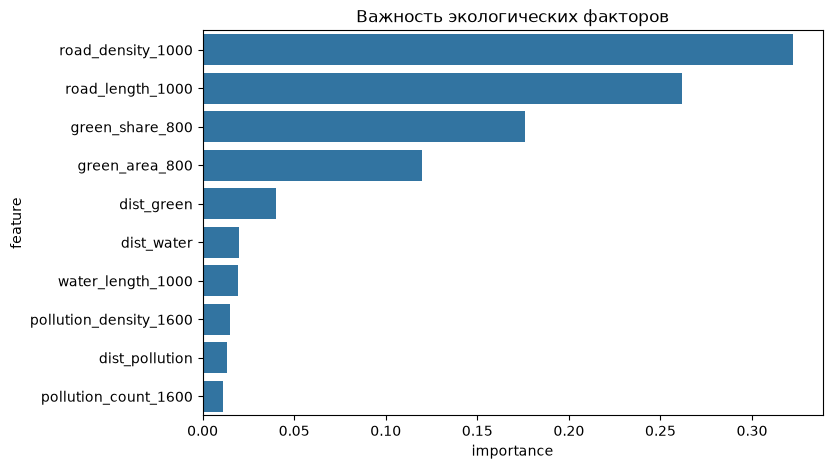

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Для классификации исключаем шумовые точки (-1)
data = grid[grid["cluster"] != -1].copy()

X = data[feature_cols]
y = data["cluster"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Gradient Boosting": GradientBoostingClassifier(),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=7)
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "f1_macro": f1_score(
            y_test,
            pred,
            average="macro"
        )
    })

results = (
    pd.DataFrame(results)
    .sort_values("f1_macro", ascending=False)
)

display(results)

best_name = results.iloc[0]["model"]
best_model = models[best_name]

pred = best_model.predict(X_test)

print("Лучшая модель:", best_name)
print()
print(classification_report(y_test, pred))

# Важность признаков Random Forest
rf = RandomForestClassifier(n_estimators=200)
rf.fit(X_train, y_train)

importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

display(importance)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=importance,
    x="importance",
    y="feature"
)
plt.title("Важность экологических факторов")
plt.show()

## **Требования к отчету (Структуре блокнота)**



1. Описание выбранной территории и источников данных
2. Методика расчета экологических показателей с обоснованием выбора буферных зон и весовых коэффициентов
3. Сравнительный анализ результатов кластеризации с обоснованием выбора оптимального алгоритма
4. Карты распределения экологических факторов и результатов кластеризации
5. Подробная характеристика выявленных экологических зон (кластеров) с рекомендациями по их развитию
6. Анализ эффективности разработанных моделей классификации
7. Выводы об экологическом состоянии исследуемой территории и возможностях практического применения полученных результатов

## **Краткий отчет**

### **1. Территория и данные**
Для исследования выбрана центральная часть Санкт-Петербурга. Чтобы работа выполнялась полностью офлайн и не зависела от доступности OpenStreetMap/Overpass API, экологические слои сформированы локально как учебные синтетические геоданные. Созданы источники загрязнения, зеленые зоны, водные объекты и крупные дороги.

### **2. Методика расчета**
Территория разбита на H3-ячейки разрешения 8. Для каждой ячейки рассчитаны пространственные показатели в буферах 800, 1000 и 1600 метров: количество и плотность источников загрязнения, площадь и процент покрытия зеленью, протяженность воды и дорог, а также расстояния до ближайших экологических объектов.

### **3. Кластеризация**
Сравниваются K-Means, агломеративная, спектральная кластеризация, DBSCAN и HDBSCAN. Оптимальное число кластеров определяется по методу локтя и внутренним метрикам: Silhouette Score, Davies-Bouldin и Calinski-Harabasz.

### **4. Интерпретация**
Более благоприятными считаются территории с высокой долей зеленых зон и водных объектов, большим расстоянием до источников загрязнения и меньшей плотностью крупных дорог. Для сравнения экологических профилей используется интегральный показатель `eco_score`.

### **5. Классификация**
Результат лучшей кластеризации используется как целевая переменная для обучения классификаторов. Сравниваются логистическая регрессия, дерево решений, случайный лес, градиентный бустинг, SVM и KNN.

### **6. Вывод**
Офлайн-подход позволяет воспроизводимо показать полный пайплайн геоэкологического анализа: создание пространственных слоев, H3-агрегацию, построение признаков, кластеризацию, картографирование и классификацию без зависимости от внешних API.
